# Stim → transformer: a minimal end-to-end decoder

**What this notebook does.** It builds a rotated surface-code memory experiment in Stim, samples detection events, turns them into the token format a transformer needs, and trains a very small transformer to predict whether the logical observable flipped. The aim is a **proof of concept that the transformer preprocessing works**, not accuracy: the model is deliberately tiny (about 17,000 parameters) and trains in a few minutes on a laptop CPU.

```
transformer_config.json  (every setting)
          │
          ▼
 1. Imports  →  2. Configuration
          │
          ▼
 3. Stim:  circuit with SI1000 noise  →  detection events + observable flip,
           separate seeds for the train / validation / test shots
          │
          ▼
 4. Transformer preprocessing:  one token per detector, placed by its Stim coordinates,
           features [event, x, y, t, is_z, is_final],  padding mask
          │
          ▼
 5. Tiny transformer:  Linear embedding → 2 encoder layers → masked mean → 1 logit,
           checked for mask and order handling, then trained
          │
          ▼
 6. Results:  test error vs. "always predict 0" and MWPM (PyMatching)
```

**How to run it.** Keep `transformer_config.json` in the same folder as this notebook, change any value in it, and run all cells (*Run All*). Nothing is imported from the project's `pipelines/` folder, so the notebook works on its own.

**Requirements.** `pip install stim numpy torch matplotlib`, plus `pymatching` for the MWPM reference (optional). The saved outputs come from Stim 1.16, NumPy 2.5, PyTorch 2.15, Matplotlib 3.11, PyMatching 2.4 and Python 3.13, on 4 CPU cores.

**One rule throughout.** The model only ever sees **detection events**, plus fixed facts about where each detector sits. It never sees the raw final data-qubit measurements or the observable; the observable is only the label.

## 1. Imports

Everything the notebook needs, grouped by job. PyMatching is optional: it only supplies the MWPM reference number in section 6, and that comparison is skipped if PyMatching isn't installed. The plot colours are set here once so both figures match.

In [1]:
# Standard library
import json                       # read the config file
import time                       # time the slow steps
from importlib.metadata import version   # report the installed package versions
from pathlib import Path          # locate the config file
from typing import Any            # type of the raw config values

# Numerics and plotting
import matplotlib.pyplot as plt   # the token picture (section 4) and the results charts (section 6)
import numpy as np                # all preprocessing is plain NumPy
from numpy.typing import NDArray  # type hints for arrays

# Quantum error correction: Stim builds the circuit and samples it
import stim

# Neural network
import torch
from torch import nn

# Optional: MWPM reference decoder for section 6. If it is missing, `pymatching` is None and the comparison is skipped.
try:
    import pymatching  # pyright: ignore[reportMissingTypeStubs]
except ImportError:
    pymatching = None

print(f"stim {version('stim')} | numpy {version('numpy')} | torch {version('torch')} | "
      f"matplotlib {version('matplotlib')} | "
      f"pymatching {version('pymatching') if pymatching is not None else 'not installed (MWPM skipped)'}")

# Plot style shared by both figures: a light surface, dark text, and two fixed colours for the two categories that
# appear (Z vs X stabilizers in section 4, training vs validation in section 6). Colour always follows the category.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "xtick.color": INK_2,
                     "ytick.color": INK_2, "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10})

stim 1.16.0 | numpy 2.5.3 | torch 2.15.0 | matplotlib 3.11.2 | pymatching 2.4.0


## 2. Configuration

Every setting lives in `transformer_config.json`, next to this notebook. JSON was chosen over a plain text file because it keeps numbers, lists and `true`/`false` as real types, and Python reads it with the standard library alone. The file has one block per stage of the notebook:

| Block | Key | Shipped value | Meaning |
|---|---|---|---|
| `stim` | `distance` | 3 | code distance d (d × d data qubits) |
| | `rounds` | 3 | rounds of stabilizer measurements (rounds = d is the usual choice) |
| | `p` | 0.003 | noise strength p |
| | `noise_model` | `"si1000"` | `"si1000"` (superconducting-inspired, the project's model) or `"uniform"` (every operation at p, as in the PDR's MWPM sweep) |
| | `basis` | `"z"` | memory-Z (`"z"`) or memory-X (`"x"`) |
| | `train_shots`, `val_shots`, `test_shots` | 200,000 / 20,000 / 100,000 | shots in each split |
| | `seed` | 1234 | base seed: train, validation and test are sampled with seed, seed + 1 and seed + 2 |
| `preprocessing` | `extra_token_features` | `[]` | optional token features: `"readings"`, `"sincos"` (section 4.4) |
| | `n_freq` | 4 | number of frequencies for `"sincos"` |
| `model` | `d_model` | 32 | length of each token's vector inside the transformer |
| | `n_heads` | 4 | attention heads (must divide `d_model`) |
| | `n_layers` | 2 | encoder layers |
| | `dim_feedforward` | 64 | hidden size of each layer's feed-forward block |
| | `dropout` | 0.0 | dropout rate inside the encoder |
| `training` | `epochs` | 8 | passes over the training shots |
| | `batch_size` | 256 | shots per gradient step |
| | `learning_rate` | 0.001 | AdamW learning rate |
| | `weight_decay` | 0.0 | AdamW weight decay |
| | `device` | `"auto"` | `"auto"` (a GPU if there is one, else the CPU), `"cpu"`, `"cuda"` or `"mps"` |
| | `torch_seed` | 0 | seed for the initial weights and the shuffling |
| `evaluation` | `compare_mwpm` | `true` | also decode the test shots with MWPM (needs PyMatching) |
| | `eval_batch_size` | 4096 | shots per forward pass when evaluating |

**Why these values.** d = 3 with 3 rounds is the smallest code with a real decoding problem: 24 detectors, so 24 tokens per shot, and training takes a couple of minutes on a CPU. SI1000 at p = 0.3% is close to today's best hardware: the project's shot-statistics sweep found that our SI1000 circuit at p ≈ 0.33% reproduces the detection rates Google reports for its Willow chip (arXiv:2408.13687), and 0.3% lies inside the 0.1% to 0.4% SI1000 range that AlphaQubit 2 trains on (Senior et al. 2025, arXiv:2512.07737). 200,000 training shots are enough to show the model learning, and 100,000 test shots pin each error rate down to within about ±0.1 to ±0.2 percentage points.

The loader below fills any key the file leaves out from the defaults, and **stops with an error on a key it doesn't know**, so a typo such as `n_layer` can't be silently ignored.

In [2]:
CONFIG_PATH = Path("transformer_config.json")   # looked up in the folder the notebook runs from

# Defaults for any key the file leaves out. The shipped transformer_config.json has exactly these values.
DEFAULT_CONFIG: dict[str, dict[str, Any]] = {
    "stim": {"distance": 3, "rounds": 3, "p": 0.003, "noise_model": "si1000", "basis": "z",
             "train_shots": 200_000, "val_shots": 20_000, "test_shots": 100_000, "seed": 1234},
    "preprocessing": {"extra_token_features": [], "n_freq": 4},
    "model": {"d_model": 32, "n_heads": 4, "n_layers": 2, "dim_feedforward": 64, "dropout": 0.0},
    "training": {"epochs": 8, "batch_size": 256, "learning_rate": 1e-3, "weight_decay": 0.0, "device": "auto",
                 "torch_seed": 0},
    "evaluation": {"compare_mwpm": True, "eval_batch_size": 4096},
}


def check(condition: bool, message: str) -> None:
    # Raise a readable error for a bad config value (instead of a confusing failure later inside Stim or PyTorch).
    if not condition:
        raise ValueError(f"transformer_config.json: {message}")


def load_config(path: Path) -> dict[str, dict[str, Any]]:
    # Read the JSON file, overlay it on the defaults, and check every value.
    if not path.exists():
        raise FileNotFoundError(f"{path.resolve()} not found: keep transformer_config.json next to this notebook")
    with open(path, encoding="utf-8") as f:
        user: dict[str, dict[str, Any]] = json.load(f)
    cfg = {block: dict(values) for block, values in DEFAULT_CONFIG.items()}   # a fresh copy of the defaults
    for block, values in user.items():
        check(block in cfg, f"unknown block {block!r}; the blocks are {list(cfg)}")
        for key, value in values.items():
            check(key in cfg[block], f"unknown key {block}.{key}; {block} has {list(cfg[block])}")
            cfg[block][key] = value
    s, pre, m, tr = cfg["stim"], cfg["preprocessing"], cfg["model"], cfg["training"]
    check(s["distance"] >= 2 and s["rounds"] >= 1, "need distance >= 2 and rounds >= 1")
    check(0 < s["p"] <= 0.1, "p is an error probability per operation; use 0 < p <= 0.1")
    check(s["noise_model"] in ("si1000", "uniform"), "noise_model must be 'si1000' or 'uniform'")
    check(s["basis"] in ("z", "x"), "basis must be 'z' or 'x'")
    check(min(s["train_shots"], s["val_shots"], s["test_shots"]) > 0, "every split needs at least one shot")
    check(set(pre["extra_token_features"]) <= {"readings", "sincos"},
          "extra_token_features may contain 'readings' and 'sincos' only")
    check(m["d_model"] % m["n_heads"] == 0, "d_model must be a multiple of n_heads")
    check(tr["device"] in ("auto", "cpu", "cuda", "mps"), "device must be 'auto', 'cpu', 'cuda' or 'mps'")
    return cfg


cfg = load_config(CONFIG_PATH)

# Unpack into named, typed settings so the rest of the notebook reads like plain code.
DISTANCE: int = cfg["stim"]["distance"]
ROUNDS: int = cfg["stim"]["rounds"]
P: float = cfg["stim"]["p"]
NOISE_MODEL: str = cfg["stim"]["noise_model"]
BASIS: str = cfg["stim"]["basis"]
TRAIN_SHOTS: int = cfg["stim"]["train_shots"]
VAL_SHOTS: int = cfg["stim"]["val_shots"]
TEST_SHOTS: int = cfg["stim"]["test_shots"]
SEED: int = cfg["stim"]["seed"]
EXTRA_FEATURES: list[str] = list(cfg["preprocessing"]["extra_token_features"])
N_FREQ: int = cfg["preprocessing"]["n_freq"]
D_MODEL: int = cfg["model"]["d_model"]
N_HEADS: int = cfg["model"]["n_heads"]
N_LAYERS: int = cfg["model"]["n_layers"]
DIM_FF: int = cfg["model"]["dim_feedforward"]
DROPOUT: float = cfg["model"]["dropout"]
EPOCHS: int = cfg["training"]["epochs"]
BATCH_SIZE: int = cfg["training"]["batch_size"]
LEARNING_RATE: float = cfg["training"]["learning_rate"]
WEIGHT_DECAY: float = cfg["training"]["weight_decay"]
DEVICE_SETTING: str = cfg["training"]["device"]
TORCH_SEED: int = cfg["training"]["torch_seed"]
COMPARE_MWPM: bool = cfg["evaluation"]["compare_mwpm"]
EVAL_BATCH: int = cfg["evaluation"]["eval_batch_size"]

print(f"Loaded {CONFIG_PATH.resolve()}")
print(json.dumps(cfg, indent=1))

Loaded /tmp/claude-0/-home-user/08f56c6a-897d-5214-abcf-b4719c637f57/scratchpad/nb/full/transformer_config.json
{
 "stim": {
  "distance": 3,
  "rounds": 3,
  "p": 0.003,
  "noise_model": "si1000",
  "basis": "z",
  "train_shots": 200000,
  "val_shots": 20000,
  "test_shots": 100000,
  "seed": 1234
 },
 "preprocessing": {
  "extra_token_features": [],
  "n_freq": 4
 },
 "model": {
  "d_model": 32,
  "n_heads": 4,
  "n_layers": 2,
  "dim_feedforward": 64,
  "dropout": 0.0
 },
 "training": {
  "epochs": 8,
  "batch_size": 256,
  "learning_rate": 0.001,
  "weight_decay": 0.0,
  "device": "auto",
  "torch_seed": 0
 },
 "evaluation": {
  "compare_mwpm": true,
  "eval_batch_size": 4096
 }
}


## 3. Stim: circuit and shots

### 3.1 The circuit and its noise model

`stim.Circuit.generated("surface_code:rotated_memory_z", ...)` writes the whole memory experiment: reset the data qubits, measure every stabilizer once per round, measure the data qubits at the end, and declare the **detectors** (pairs of measurements that agree when nothing went wrong) and the **logical observable** (the parity that says whether the stored logical qubit flipped).

Stim's generator has only four noise settings (after gates, on data qubits before each round, before measurements, after resets), which can't express SI1000's rules, so SI1000 noise is added by hand, moment by moment (from one `TICK` to the next), following Gidney, Newman, Fowler and Broughton, *A Fault-Tolerant Honeycomb Memory* (2021), Table 2:

| Operation | Noise added (strength p) |
|---|---|
| two-qubit gate (CX) | `DEPOLARIZE2(p)` after the gate |
| single-qubit gate (H) | `DEPOLARIZE1(p/10)` after the gate |
| reset | bit flip with probability 2p after the reset |
| measurement | result flipped with probability 5p |
| qubit idle in a moment | `DEPOLARIZE1(p/10)` |
| qubit idle while other qubits are measured or reset | `DEPOLARIZE1(2p)` |

**Why SI1000.** It is the project's chosen noise model because it looks like superconducting hardware: measurement and reset are much noisier than gates (5p = 1.5% measurement error at p = 0.3%), and qubits that wait during the slow measurement step pick up extra noise. The function below is the same one as in `analysis/shot_stats_sweep.py`, copied here so the notebook runs on its own. `noise_model = "uniform"` gives the PDR's model instead: every gate, reset, measurement and idle data qubit at p.

In [3]:
# Instruction names in Stim's generated surface-code circuits, grouped by the noise rule SI1000 gives them.
ONE_QUBIT_GATES = {"H", "S", "S_DAG", "SQRT_X", "SQRT_X_DAG", "SQRT_Y", "SQRT_Y_DAG", "X", "Y", "Z", "I"}
TWO_QUBIT_GATES = {"CX", "CNOT", "CY", "CZ", "SWAP", "ISWAP", "ISWAP_DAG", "XCZ", "YCZ"}
RESETS = {"R", "RZ", "RX", "RY"}
MEASUREMENTS = {"M", "MZ", "MX", "MY"}
MEASURE_RESETS = {"MR", "MRZ", "MRX", "MRY"}
ANNOTATIONS = {"DETECTOR", "OBSERVABLE_INCLUDE", "SHIFT_COORDS", "QUBIT_COORDS"}   # bookkeeping, no noise


def add_si1000_noise(clean: stim.Circuit, p: float) -> stim.Circuit:
    # Return a copy of a noiseless circuit with SI1000 noise added (table above), one moment (TICK to TICK) at a time.
    used: set[int] = set()   # every qubit the circuit touches; the ones a moment leaves alone are "idle" in it
    for inst in clean.flattened():           # flattened() unrolls REPEAT blocks into plain instructions
        if isinstance(inst, stim.CircuitInstruction) and inst.name not in ANNOTATIONS | {"TICK"}:
            used.update(t.value for t in inst.targets_copy() if t.is_qubit_target)

    def flip_for(name: str) -> str:
        # An X-basis reset or measurement (RX, MX, MRX) is spoiled by a Z flip; every other one by an X flip.
        return "Z_ERROR" if name.endswith("X") else "X_ERROR"

    def moment(ops: list[stim.CircuitInstruction], out: stim.Circuit) -> None:
        # Copy one moment's operations to `out`, each followed by its noise, then add idle noise.
        touched: set[int] = set()
        measures_or_resets = False
        for inst in ops:
            name = inst.name
            qubits = [t.value for t in inst.targets_copy() if t.is_qubit_target]
            if name in ANNOTATIONS:
                out.append(inst)
                continue
            touched.update(qubits)
            if name in ONE_QUBIT_GATES:
                out.append(inst)
                out.append("DEPOLARIZE1", qubits, p / 10)
            elif name in TWO_QUBIT_GATES:
                out.append(inst)
                out.append("DEPOLARIZE2", qubits, p)
            elif name in RESETS:
                measures_or_resets = True
                out.append(inst)
                out.append(flip_for(name), qubits, 2 * p)
            elif name in MEASUREMENTS | MEASURE_RESETS:
                measures_or_resets = True
                # Stim's measurement argument is the probability that the reported result is flipped.
                out.append(stim.CircuitInstruction(name, inst.targets_copy(), [5 * p]))
                if name in MEASURE_RESETS:
                    out.append(flip_for(name), qubits, 2 * p)
            else:
                raise ValueError(f"SI1000: no noise rule for {name}")
        idle = [q for q in sorted(used) if q not in touched]
        if idle and touched:
            out.append("DEPOLARIZE1", idle, 2 * p if measures_or_resets else p / 10)

    def walk(circuit: stim.Circuit) -> stim.Circuit:
        # Split the circuit into moments at each TICK; REPEAT blocks (the bulk rounds) are handled recursively.
        out = stim.Circuit()
        ops: list[stim.CircuitInstruction] = []
        for inst in circuit:
            if isinstance(inst, stim.CircuitRepeatBlock):
                moment(ops, out)
                ops.clear()
                out.append(stim.CircuitRepeatBlock(inst.repeat_count, walk(inst.body_copy())))
            elif inst.name == "TICK":
                moment(ops, out)
                ops.clear()
                out.append(inst)
            else:
                ops.append(inst)
        moment(ops, out)
        return out

    return walk(clean)


def make_circuit(distance: int, rounds: int, p: float, basis: str, noise_model: str) -> stim.Circuit:
    # Rotated surface-code memory experiment with SI1000 or uniform circuit noise of strength p.
    task = f"surface_code:rotated_memory_{basis}"
    if noise_model == "uniform":
        return stim.Circuit.generated(task, distance=distance, rounds=rounds,
                                      after_clifford_depolarization=p, before_measure_flip_probability=p,
                                      after_reset_flip_probability=p, before_round_data_depolarization=p)
    return add_si1000_noise(stim.Circuit.generated(task, distance=distance, rounds=rounds), p)


circuit = make_circuit(DISTANCE, ROUNDS, P, BASIS, NOISE_MODEL)
NUM_DETECTORS = circuit.num_detectors

# d^2 data qubits + d^2 - 1 measure qubits. Count them from the coordinates: Stim's num_qubits is the largest qubit
# index + 1, and the generated circuit skips some indices. A memory experiment has exactly one logical observable.
n_qubits = len(circuit.get_final_qubit_coordinates())
print(f"d = {DISTANCE}, rounds = {ROUNDS}, memory-{BASIS.upper()}, {NOISE_MODEL} noise at p = {P}")
print(f"{n_qubits} qubits ({DISTANCE ** 2} data + {DISTANCE ** 2 - 1} measure), {NUM_DETECTORS} detectors, "
      f"{circuit.num_observables} logical observable (the label)")
assert n_qubits == 2 * DISTANCE ** 2 - 1 and circuit.num_observables == 1

d = 3, rounds = 3, memory-Z, si1000 noise at p = 0.003
17 qubits (9 data + 8 measure), 24 detectors, 1 logical observable (the label)


### 3.2 Sample the shots

A compiled detector sampler draws whole shots at once. With `separate_observables=True` it returns:

- `dets`: bool `[shots, 24]`, the detection events in **Stim's detector order** (the order the `DETECTOR` lines appear in the circuit).
- `obs`: bool `[shots, 1]`, whether the logical observable flipped. This is the **label**, never an input.

**Separate seeds per split** (step 5 of the data notes). Train, validation and test come from three separate sampler calls with seeds `seed`, `seed + 1` and `seed + 2`, so the test shots are independent of the training shots, and sampling more training data later can't leak into the test set. Shuffling of whole shots happens later, in the training loop. This step applies to every model, so it is part of the data generation rather than the transformer preprocessing. (Stim only promises identical shots for the same seed on the same Stim version and machine, so a rerun elsewhere gives slightly different numbers.)

In [4]:
BoolArray = NDArray[np.bool_]


def sample_shots(circuit: stim.Circuit, shots: int, seed: int) -> tuple[BoolArray, BoolArray]:
    # One sampler call: (detection events [shots, D], observable flips [shots, 1]), both bool.
    sampler = circuit.compile_detector_sampler(seed=seed)
    dets, obs = sampler.sample(shots, separate_observables=True)
    return dets.astype(np.bool_), obs.astype(np.bool_)


t0 = time.perf_counter()
train_dets, train_obs = sample_shots(circuit, TRAIN_SHOTS, SEED)       # seed
val_dets, val_obs = sample_shots(circuit, VAL_SHOTS, SEED + 1)         # seed + 1
test_dets, test_obs = sample_shots(circuit, TEST_SHOTS, SEED + 2)      # seed + 2
print(f"sampled {TRAIN_SHOTS + VAL_SHOTS + TEST_SHOTS:,} shots in {time.perf_counter() - t0:.2f} s")
print(f"train_dets {train_dets.shape} {train_dets.dtype}, train_obs {train_obs.shape} {train_obs.dtype}")

sampled 320,000 shots in 0.05 s
train_dets (200000, 24) bool, train_obs (200000, 1) bool


### 3.3 What the data looks like

Three numbers that matter for reading the results:

- **Empty shots**: no detector fired. The right answer for these is almost always "no flip".
- **Label = 1**: the share of shots whose observable flipped. This is the raw flip, not a decoder failure, and it is exactly the error rate of the trivial decoder that always answers 0. Any model that learned something from the detectors must beat it.
- **Detector firing rate**: how often an average detector fires (the hardware-comparable "detection probability").

In [5]:
for name, dets, obs in [("train", train_dets, train_obs), ("val", val_dets, val_obs), ("test", test_dets, test_obs)]:
    print(f"{name:>5}: {len(dets):>7,} shots | empty {100 * np.mean(~dets.any(axis=1)):5.1f}% | "
          f"label = 1 {100 * obs.mean():5.2f}% | detector firing rate {100 * dets.mean():4.2f}% | "
          f"mean events per shot {dets.sum(axis=1).mean():.2f}")

train: 200,000 shots | empty  34.5% | label = 1 12.24% | detector firing rate 6.94% | mean events per shot 1.67
  val:  20,000 shots | empty  34.3% | label = 1 12.19% | detector firing rate 6.98% | mean events per shot 1.68
 test: 100,000 shots | empty  34.4% | label = 1 12.28% | detector firing rate 6.97% | mean events per shot 1.67


## 4. Transformer preprocessing

A transformer reads a **set of tokens**. Attention compares every token with every other one, which is what lets it pick up correlations across the whole code, but it has no built-in notion of order: shuffle the tokens and it computes the same thing (section 5.2 checks this). So everything a decoder needs to know about *where* and *when* a detector sits has to be written into each token. That is the whole job of the preprocessing here.

**Steps taken** (numbers are the steps of the team's QEC Decoder Data Notes, as in `notes/preprocessing_steps_explained.md`):

| Step | What it does | Why the transformer needs it |
|---|---|---|
| Place detectors by Stim coordinates (1) | reads each detector's (x, y, t) from the circuit | Stim's detector index is not a position: it shifts with d and rounds, and the first and last slices hold only half the stabilizers |
| One token per real detector | 24 tokens at d = 3, 3 rounds, sorted by (t, y, x) | the X stabilizers that have no detector in the first and last slices simply get no token, so no "valid" mask channel is needed |
| Position features x, y, t | each token carries its stabilizer's position and its time slice | attention can't see order, so without these it would see an unordered bag of 0s and 1s |
| Stabilizer type `is_z` (6) | 1 for Z stabilizers, 0 for X | X and Z stabilizers catch different errors; the type is a checkerboard pattern of (x, y), which the model would otherwise have to learn from the positions |
| Final-slice flag `is_final` (3) | 1 for the last slice | those detectors compare the last stabilizer round with the data-qubit readout, not two stabilizer rounds, so they behave differently |
| float32 tokens, label kept apart (4) | `tokens` float32 `[B, N, F]`; label `obs` only used in the loss | layers need floats; keeping the label out of the inputs means the model can't see the answer |
| Padding mask | bool `[B, N]`, True = padded token | how a transformer takes shots of different sizes in one batch; all False for one code, but the model uses it and section 5.2 checks it |
| *Optional:* `readings`, `sincos` | see 4.4 | off by default to keep the proof of concept minimal |

**Steps skipped, and why**

| Skipped | Reason |
|---|---|
| Flat Stim-order row (MLP format) | the transformer needs one token per detector with its own features, not one long vector |
| `valid` mask channel (2) | it marks grid slots that have no detector; tokens only exist for real detectors, so there is nothing to mark except padding |
| 2D image layout (7), per-round sequence, DEM graph | the CNN, RNN and GNN formats |
| Noise prior | at a single noise level it is the same for every shot, so it adds nothing; it matters when training spans several p |
| Basis flag (9) | one run uses one basis |
| Drop empty shots (11) | a training-time saving for any model; skipped so the model also trains on the empty shots it meets at test time |
| Mixing noise levels or round counts (8, 12) | one config is one code at one p |
| Feature scaling, stabilizer dropout | scaling only matters for the prior; dropout is a regulariser, not needed for a proof of concept |

### 4.1 Read where every detector sits

`circuit.get_detector_coordinates()` gives each detector its (x, y, t): (x, y) is the position of the stabilizer it belongs to, and t is the time slice, 0 to `rounds`. The rows below show the problem with using the index as a position. At d = 3, indices 0 to 3 are slice 0 (Z stabilizers only), indices 4 to 11 are slice 1 (X and Z mixed), and the same stabilizer has a different index in every slice.

In [6]:
coords = circuit.get_detector_coordinates()                          # {detector index: [x, y, t]}
det_xyt = np.array([coords[k] for k in range(NUM_DETECTORS)], dtype=np.float64)
assert det_xyt.shape == (NUM_DETECTORS, 3), "expected (x, y, t) coordinates for every detector"

N_SLICES = int(det_xyt[:, 2].max()) + 1                              # time slices 0 .. rounds
print(f"det_xyt {det_xyt.shape}: one (x, y, t) row per detector, {N_SLICES} time slices\n")
print("Stim index -> (x, y, t)")
for k in range(min(12, NUM_DETECTORS)):
    x, y, t = det_xyt[k]
    print(f"  {k:>3} -> ({x:.0f}, {y:.0f}, {t:.0f})")

det_xyt (24, 3): one (x, y, t) row per detector, 4 time slices

Stim index -> (x, y, t)
    0 -> (0, 4, 0)
    1 -> (2, 2, 0)
    2 -> (4, 4, 0)
    3 -> (6, 2, 0)
    4 -> (2, 0, 1)
    5 -> (2, 2, 1)
    6 -> (4, 2, 1)
    7 -> (6, 2, 1)
    8 -> (0, 4, 1)
    9 -> (2, 4, 1)
   10 -> (4, 4, 1)
   11 -> (4, 6, 1)


### 4.2 One token per detector, in a fixed order

Each detector becomes one token. `np.lexsort` sorts by its **last** key first, so `lexsort((x, y, t))` orders tokens by time slice, then row y, then column x. `token_order[k]` is the Stim index of token k, and `dets[:, token_order]` reads every shot in token order.

**Why sort at all, if the transformer ignores order?** The model's output doesn't depend on it (checked in 5.2). The sort is for everything around the model: tokens grouped by round are easy to read, easy to check against the circuit, and ready for a causal "only look at earlier rounds" mask if the model ever has to decode in real time. Any fixed rule would do, as long as it is the same for every shot.

In [7]:
# Sort by t (primary), then y, then x. lexsort's LAST key is the primary one.
token_order = np.lexsort((det_xyt[:, 0], det_xyt[:, 1], det_xyt[:, 2]))   # [N] Stim index of each token
N_TOKENS = len(token_order)                                                   # one token per real detector

tok_x = det_xyt[token_order, 0]          # stabilizer column, 0 .. 2d (Stim's own units)
tok_y = det_xyt[token_order, 1]          # stabilizer row, 0 .. 2d
tok_t = det_xyt[token_order, 2]          # time slice, 0 .. rounds
tok_round = tok_t.astype(np.int64)

# Stabilizer index per token: number the distinct (x, y) positions. Used by the "readings" option and the figure.
stab_xy, tok_stab = np.unique(det_xyt[token_order, :2], axis=0, return_inverse=True)
tok_stab = tok_stab.reshape(-1)
N_STABS = len(stab_xy)

print(f"{N_TOKENS} tokens per shot from {N_STABS} distinct stabilizer positions")
print("first 8 tokens (token -> Stim index):", {k: int(token_order[k]) for k in range(min(8, N_TOKENS))})

24 tokens per shot from 8 distinct stabilizer positions
first 8 tokens (token -> Stim index): {0: 1, 1: 3, 2: 0, 3: 2, 4: 4, 5: 5, 6: 6, 7: 7}


### 4.3 Stabilizer type and final-slice flag

**Type.** In a memory-Z experiment the first slice only has detectors on Z stabilizers: the data qubits start in a Z eigenstate, so the Z stabilizers' first results are known in advance, while the X stabilizers' first results are random and only become meaningful when compared with the next round's results. So the positions that appear in slice 0 are exactly the memory-basis stabilizers (Z for memory-Z, X for memory-X). This reads the type straight from the circuit, without assuming any particular layout.

**Final slice.** The last slice (t = rounds) is built from the data-qubit measurements at the end, so it only exists for the memory-basis stabilizers too.

The table confirms both: the first and last slices have only Z tokens, the middle slices have both types. The **missing X detectors** in the first and last slices are handled simply by having no token for them.

In [8]:
# Positions with a detector in slice 0 = the memory-basis stabilizers.
basis_positions = {(float(x), float(y)) for x, y, t in det_xyt if t == 0}
tok_is_basis = np.array([(x, y) in basis_positions for x, y in zip(tok_x, tok_y)])
tok_is_z = tok_is_basis if BASIS == "z" else ~tok_is_basis    # memory-X: the basis stabilizers are the X ones
tok_is_final = tok_round == N_SLICES - 1

print("slice | tokens |  Z |  X | final")
for t in range(N_SLICES):
    in_t = tok_round == t
    print(f"{t:>5} | {in_t.sum():>6} | {np.sum(in_t & tok_is_z):>2} | {np.sum(in_t & ~tok_is_z):>2} | "
          f"{'yes' if tok_is_final[in_t].all() else 'no'}")

slice | tokens |  Z |  X | final
    0 |      4 |  4 |  0 | no
    1 |      8 |  4 |  4 | no
    2 |      8 |  4 |  4 | no
    3 |      4 |  4 |  0 | yes


### 4.4 The fixed token features

Everything except the detection event is the same in every shot, so it is computed once here, as a `[N, F_static]` array, and copied into each batch.

| Feature | Value | Scaling decision |
|---|---|---|
| `x`, `y` | stabilizer position / (2d) − 0.5 | Stim's coordinates run from 0 to 2d; this maps every code to [−0.5, 0.5], about the same size as the 0/1 features, and the centre of the code to 0 |
| `t` | slice / rounds | [0, 1]: 0 is the first slice and 1 the final readout, whatever the number of rounds |
| `is_z`, `is_final` | 0 or 1 | already on the right scale; no normalisation, since subtracting a mean would make "no" a different negative number per token |

**Optional features** (`extra_token_features` in the config):

- `"readings"`: the stabilizer's current value, the running XOR of its own events up to this slice (step 10 of the data notes). An event says "this stabilizer changed"; the reading says what it is now. It is computed from the events, so it adds no new information, but AlphaQubit trained better with both. It changes per shot, so it is filled in by `make_tokens` in 4.5.
- `"sincos"`: sin and cos of the round index at `n_freq` frequencies, the original transformer's position encoding. Only useful if a model must run on more rounds than it was trained on, because `t` is rescaled per experiment.

In [9]:
# Fixed features for every token, one column each. Values are float32 because the network computes in float32.
static_columns: dict[str, NDArray[np.float64]] = {
    "x": tok_x / (2 * DISTANCE) - 0.5,             # [-0.5, 0.5]
    "y": tok_y / (2 * DISTANCE) - 0.5,             # [-0.5, 0.5]
    "t": tok_t / max(N_SLICES - 1, 1),             # [0, 1]
    "is_z": tok_is_z.astype(np.float64),           # 1 = Z stabilizer, 0 = X
    "is_final": tok_is_final.astype(np.float64),   # 1 = final data-qubit readout slice
}
if "sincos" in EXTRA_FEATURES:
    freqs = 10000.0 ** (-np.arange(N_FREQ) / N_FREQ)            # w_k = 10000^(-k / n_freq), as in the original transformer
    for k, w in enumerate(freqs):
        static_columns[f"sin{k}"] = np.sin(tok_round * w)
        static_columns[f"cos{k}"] = np.cos(tok_round * w)

STATIC_NAMES = list(static_columns)
static_features = np.stack([static_columns[n] for n in STATIC_NAMES], axis=1).astype(np.float32)   # [N, F_static]

# Full feature list, in the order of the token's last axis: per-shot features first, then the fixed ones.
PER_SHOT_NAMES = ["event"] + (["readings"] if "readings" in EXTRA_FEATURES else [])
TOKEN_FEATURES = PER_SHOT_NAMES + STATIC_NAMES
N_FEATURES = len(TOKEN_FEATURES)
print(f"static_features {static_features.shape}; token features ({N_FEATURES}): {TOKEN_FEATURES}")

static_features (24, 5); token features (6): ['event', 'x', 'y', 't', 'is_z', 'is_final']


### 4.5 The per-shot features and `make_tokens`

`make_tokens(dets)` is the whole preprocessing for one batch of shots: it reads the events in token order, adds the readings if they are switched on, and appends the fixed features.

**Built per minibatch, not in advance.** One shot is 24 bits from Stim but 24 × 6 float32 = 576 bytes as tokens, so the notebook keeps Stim's compact bool arrays and calls `make_tokens` on each minibatch inside the training loop. It costs well under a millisecond per batch, and the same code would handle a million shots at d = 5 without running out of memory.

**The padding mask.** Every shot of one code has the same N tokens, so the mask returned here is all False. It is still part of the format because it is how a transformer handles shots of different sizes: to mix d = 3 and d = 5 in one batch, the shorter shots get dummy tokens at the end, flagged True, and the model must ignore them. PyTorch's convention is used: **True = padding, ignore this token**.

In [10]:
FloatArray = NDArray[np.float32]


def make_tokens(dets: BoolArray) -> tuple[FloatArray, BoolArray]:
    # Stim detection events bool [B, D] (Stim order) -> tokens float32 [B, N, F] and pad_mask bool [B, N].
    B = dets.shape[0]
    events = dets[:, token_order]                             # [B, N]: the same bits, now in token order
    per_shot = [events.astype(np.float32)]
    if "readings" in EXTRA_FEATURES:
        # Running XOR over time of each stabilizer's events. Put the events on a [B, slice, stabilizer] grid (slots
        # with no detector stay 0, which leaves the XOR unchanged), accumulate along time, read back per token.
        grid = np.zeros((B, N_SLICES, N_STABS), dtype=np.bool_)
        grid[:, tok_round, tok_stab] = events
        readings = np.logical_xor.accumulate(grid, axis=1)[:, tok_round, tok_stab]
        per_shot.append(readings.astype(np.float32))
    tokens = np.empty((B, N_TOKENS, N_FEATURES), dtype=np.float32)
    tokens[:, :, :len(per_shot)] = np.stack(per_shot, axis=2)   # per-shot features first
    tokens[:, :, len(per_shot):] = static_features               # fixed features, broadcast to every shot
    pad_mask = np.zeros((B, N_TOKENS), dtype=np.bool_)          # one code: no padding
    return tokens, pad_mask


demo_tokens, demo_mask = make_tokens(test_dets[:4])
print(f"tokens {demo_tokens.shape} {demo_tokens.dtype}, pad_mask {demo_mask.shape} {demo_mask.dtype}")
t0 = time.perf_counter()
make_tokens(train_dets[:BATCH_SIZE])
print(f"make_tokens on one batch of {BATCH_SIZE} shots: {1e3 * (time.perf_counter() - t0):.2f} ms")

tokens (4, 24, 6) float32, pad_mask (4, 24) bool
make_tokens on one batch of 256 shots: 0.55 ms


### 4.6 Checks: nothing lost, nothing added

1. **Round trip.** Reading the event feature back into Stim's order must give exactly the sampled detection events, for every test shot. That proves the preprocessing only rearranges the bits and annotates them.
2. **One shot, token by token.** The fired tokens of one test shot, with their position, type and slice.
3. **Picture of the same shot.** Each time slice of the d × d code (the first two and last two if there are more than four): which stabilizers have a token in that slice (the X ones are missing in the first and last), and which fired.

In [11]:
# 1. Round trip: tokens -> Stim order. dets_back[:, token_order[k]] = event feature of token k.
all_tokens, _ = make_tokens(test_dets)
dets_back = np.zeros_like(test_dets)
dets_back[:, token_order] = all_tokens[:, :, 0] > 0.5
assert np.array_equal(dets_back, test_dets)
print(f"Round trip exact on all {len(test_dets):,} test shots: tokens hold exactly Stim's detection events.")
if "readings" in EXTRA_FEATURES:
    r_col = TOKEN_FEATURES.index("readings")
    # Each reading changes exactly when its stabilizer has an event, so XOR with the previous reading = the event.
    prev = np.zeros_like(all_tokens[:, :, r_col])
    for t in range(1, N_SLICES):
        for s in range(N_STABS):
            here = np.where((tok_round == t) & (tok_stab == s))[0]
            before = np.where((tok_round == t - 1) & (tok_stab == s))[0]
            if len(here) and len(before):
                prev[:, here[0]] = all_tokens[:, before[0], r_col]
    assert np.array_equal((all_tokens[:, :, r_col] > 0.5) ^ (prev > 0.5), all_tokens[:, :, 0] > 0.5)
    print("Readings check: every change in a stabilizer's reading is one of its events, and vice versa.")
del all_tokens

# 2. One test shot with a few events, as a table of its fired tokens.
n_events = test_dets.sum(axis=1)
shot = int(np.flatnonzero((n_events >= 3) & (n_events <= 5))[0])
shot_tokens, _ = make_tokens(test_dets[shot:shot + 1])
fired = np.flatnonzero(shot_tokens[0, :, 0])
print(f"\nTest shot {shot}: {len(fired)} of {N_TOKENS} tokens fired, label (observable flip) = {int(test_obs[shot, 0])}")
print("token | Stim index | slice | (x, y) | type | final | feature vector")
for k in fired:
    vec = ", ".join(f"{v:+.2f}" for v in shot_tokens[0, k])
    print(f"{k:>5} | {token_order[k]:>10} | {tok_round[k]:>5} | ({tok_x[k]:.0f}, {tok_y[k]:.0f}) | "
          f"{'Z' if tok_is_z[k] else 'X':>4} | {'yes' if tok_is_final[k] else 'no':>5} | [{vec}]")
print("features:", TOKEN_FEATURES)

Round trip exact on all 100,000 test shots: tokens hold exactly Stim's detection events.

Test shot 5: 4 of 24 tokens fired, label (observable flip) = 0
token | Stim index | slice | (x, y) | type | final | feature vector
    6 |          6 |     1 | (4, 2) |    X |    no | [+1.00, +0.17, -0.17, +0.33, +0.00, +0.00]
    7 |          7 |     1 | (6, 2) |    Z |    no | [+1.00, +0.50, -0.17, +0.33, +1.00, +0.00]
   10 |         10 |     1 | (4, 4) |    Z |    no | [+1.00, +0.17, +0.17, +0.33, +1.00, +0.00]
   14 |         14 |     2 | (4, 2) |    X |    no | [+1.00, +0.17, -0.17, +0.67, +0.00, +0.00]
features: ['event', 'x', 'y', 't', 'is_z', 'is_final']


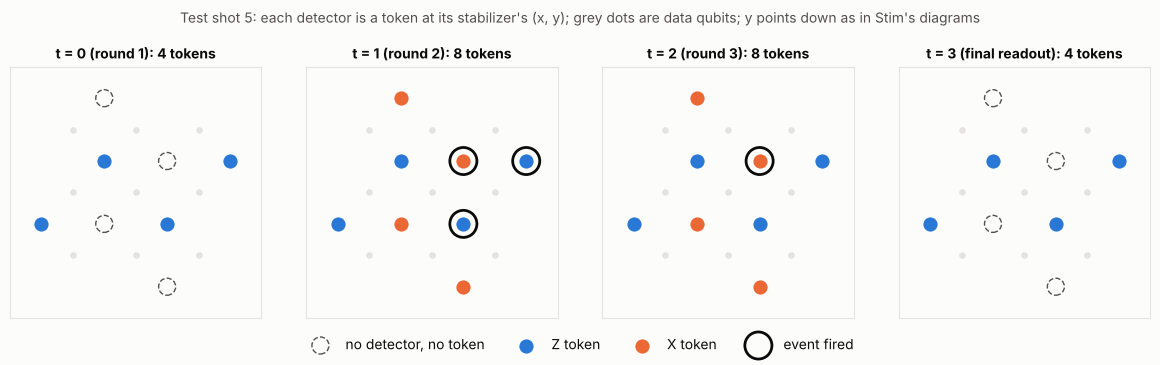

In [12]:
# 3. The same shot drawn on the code: every time slice when there are at most 4, else the first two and the last two.
slices_to_draw = list(range(N_SLICES)) if N_SLICES <= 4 else [0, 1, N_SLICES - 2, N_SLICES - 1]
fig, axes = plt.subplots(1, len(slices_to_draw), figsize=(3.0 * len(slices_to_draw), 3.6))
data_xy = [(x, y) for x in range(1, 2 * DISTANCE, 2) for y in range(1, 2 * DISTANCE, 2)]
for ax, t in zip(np.atleast_1d(axes), slices_to_draw):
    ax.scatter([x for x, _ in data_xy], [y for _, y in data_xy], s=14, color=GRID, zorder=1)        # data qubits
    in_t = tok_round == t
    has_token = {(x, y) for x, y in zip(tok_x[in_t], tok_y[in_t])}
    no_token = [(x, y) for x, y in stab_xy if (x, y) not in has_token]
    if no_token:                                                                                  # missing X detectors
        ax.scatter(*zip(*no_token), s=150, facecolors="none", edgecolors=INK_2, linestyles="--", linewidths=1,
                   zorder=2, label="no detector, no token")
    for is_z, colour, name in [(True, BLUE, "Z token"), (False, ORANGE, "X token")]:
        sel = in_t & (tok_is_z == is_z)
        if sel.any():
            ax.scatter(tok_x[sel], tok_y[sel], s=150, color=colour, edgecolors=SURFACE, linewidths=2, zorder=3,
                       label=name)
    hit = in_t & (shot_tokens[0, :, 0] > 0.5)
    if hit.any():
        ax.scatter(tok_x[hit], tok_y[hit], s=380, facecolors="none", edgecolors=INK, linewidths=2, zorder=4,
                   label="event fired")
    # Slice t < rounds compares stabilizer round t + 1 with the round before; the last slice is the data readout.
    title = "final readout" if t == N_SLICES - 1 else f"round {t + 1}"
    ax.set_title(f"t = {t} ({title}): {int(in_t.sum())} tokens", fontsize=10)
    ax.set_xlim(-1, 2 * DISTANCE + 1)
    ax.set_ylim(2 * DISTANCE + 1, -1)       # y downwards, as in Stim's diagrams
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
handles: dict[str, Any] = {}
for ax in np.atleast_1d(axes):
    for h, lab in zip(*ax.get_legend_handles_labels()):
        handles.setdefault(lab, h)
fig.legend(list(handles.values()), list(handles.keys()), loc="lower center", ncol=4, frameon=False)
fig.suptitle(f"Test shot {shot}: each detector is a token at its stabilizer's (x, y); grey dots are data qubits; "
             f"y points down as in Stim's diagrams",
             fontsize=10, color=INK_2)
fig.tight_layout(rect=(0, 0.08, 1, 0.95))
plt.show()

## 5. The transformer

### 5.1 The model

```
tokens [B, N, F]                       F = 6 features per token (event, x, y, t, is_z, is_final)
   │  Linear(F → d_model)              token embedding: one learned vector per feature, summed
   ▼
[B, N, d_model]
   │  TransformerEncoder × n_layers    each layer: LayerNorm → 4-head self-attention → + residual
   │  (padding mask applied here)                  LayerNorm → feed-forward (d_model → 64 → d_model) → + residual
   ▼
[B, N, d_model]  → LayerNorm
   │  masked mean over real tokens     one vector per shot; padded tokens don't count
   ▼
[B, d_model]
   │  Linear(d_model → 1)
   ▼
logit [B, 1]                           P(observable flipped) = sigmoid(logit); predict 1 when logit > 0
```

**Decisions, and why**

- **One `Linear` layer embeds all features.** A linear layer applied to a 0/1 flag such as `is_z` adds one learned vector when the flag is 1, which is exactly what an `nn.Embedding` with two rows would do. So one layer covers events, positions, type and the final flag, with no separate embedding tables.
- **No extra positional encoding.** The position is already in every token (x, y, t). Because it is given as numbers rather than as a learned vector per stabilizer, the same weights could run on another distance or round count.
- **Pre-LayerNorm layers** (`norm_first=True`). They train stably without a learning-rate warm-up, which keeps the training loop to the bare minimum.
- **Masked mean instead of a [CLS] token.** Averaging the token outputs gives one vector per shot without adding a special token, and leaving out the padded tokens makes the result independent of padding.
- **Tiny size**: d_model = 32, 4 heads, 2 layers, about 17,000 parameters. Enough to show the format works; nowhere near enough to aim for accuracy.
- **No dropout.** The tiny model sees 200,000 simulated shots, and in the saved run training and validation loss track each other (section 6), so there is no overfitting to fight.
- **`batch_first=True`**, so the tensors keep the `[B, N, F]` layout the preprocessing produces. **`enable_nested_tensor=False`** only silences a PyTorch warning: its nested-tensor shortcut doesn't apply to pre-LayerNorm layers anyway.
- **Output is one logit**, trained with `BCEWithLogitsLoss` (binary cross-entropy computed from the logit, which is numerically safer than applying a sigmoid first).

In [13]:
class TinyTransformerDecoder(nn.Module):
    # Tokens [B, N, F] + padding mask [B, N] (True = padding) -> one logit per shot [B, 1].

    def __init__(self, n_features: int, d_model: int, n_heads: int, n_layers: int, dim_feedforward: int,
                 dropout: float) -> None:
        super().__init__()
        self.embed = nn.Linear(n_features, d_model)                   # token features -> d_model vector
        layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_feedforward, dropout,
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        self.head = nn.Linear(d_model, 1)                             # shot vector -> logit

    def forward(self, tokens: torch.Tensor, pad_mask: torch.Tensor) -> torch.Tensor:
        h = self.embed(tokens)                                        # [B, N, d_model]
        h = self.encoder(h, src_key_padding_mask=pad_mask)            # attention never reads a padded token
        keep = (~pad_mask).unsqueeze(-1).to(h.dtype)                  # [B, N, 1]: 1 = real token
        pooled = (h * keep).sum(dim=1) / keep.sum(dim=1).clamp(min=1.0)   # mean over real tokens only
        return self.head(pooled)                                      # [B, 1]


# Device: "auto" picks a CUDA GPU, then Apple's MPS, then the CPU. The model is small enough for any of them.
if DEVICE_SETTING == "auto":
    device = torch.device("cuda" if torch.cuda.is_available() else
                          "mps" if torch.backends.mps.is_available() else "cpu")
else:
    device = torch.device(DEVICE_SETTING)

torch.manual_seed(TORCH_SEED)                                         # same initial weights on every run
model = TinyTransformerDecoder(N_FEATURES, D_MODEL, N_HEADS, N_LAYERS, DIM_FF, DROPOUT).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"device: {device}; {n_params:,} trainable parameters")
print(model)

device: cpu; 17,409 trainable parameters
TinyTransformerDecoder(
  (embed): Linear(in_features=6, out_features=32, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=64, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=64, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
    (norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (head): Linear(in_features=32, out_features=1, bias=True)
)


### 5.2 Checks before training: the mask and the token order

These hold for any weights, so they run on the untrained model.

1. **Padding is ignored.** Append 7 dummy tokens filled with random numbers to a few real shots and flag them True in the mask. The output must not change.
2. **Negative control.** Same padded input, but with the mask left all False. Now the model reads the junk and the output must change. Without this, check 1 could pass for the wrong reason (for example a model that ignores the mask *and* happens to be insensitive).
3. **Token order doesn't matter.** Shuffle the tokens (and the mask with them). The output must not change, which is why every token has to carry its own position (section 4).

In [14]:
def to_torch(tokens: FloatArray, pad_mask: BoolArray) -> tuple[torch.Tensor, torch.Tensor]:
    # NumPy arrays from make_tokens -> tensors on the model's device.
    return torch.from_numpy(tokens).to(device), torch.from_numpy(pad_mask).to(device)


model.eval()
check_tokens, check_mask = make_tokens(test_dets[:16])
with torch.no_grad():
    x, m = to_torch(check_tokens, check_mask)
    reference = model(x, m)

    # 1. Padding: 7 junk tokens per shot, flagged True.
    n_pad = 7
    junk = torch.randn(x.shape[0], n_pad, x.shape[2], device=device) * 5.0
    x_pad = torch.cat([x, junk], dim=1)
    m_pad = torch.cat([m, torch.ones(m.shape[0], n_pad, dtype=torch.bool, device=device)], dim=1)
    padded = model(x_pad, m_pad)

    # 2. Negative control: the same junk tokens, but the mask says they are real.
    unmasked = model(x_pad, torch.zeros_like(m_pad))

    # 3. Shuffle the tokens of every shot the same way.
    perm = torch.randperm(x.shape[1], device=device)
    shuffled = model(x[:, perm], m[:, perm])

print(f"1. padded vs original:        max |difference| = {(padded - reference).abs().max().item():.1e}  (should be ~0)")
print(f"2. junk read as real tokens:  max |difference| = {(unmasked - reference).abs().max().item():.1e}  (should be clearly > 0)")
print(f"3. tokens shuffled:           max |difference| = {(shuffled - reference).abs().max().item():.1e}  (should be ~0)")
assert torch.allclose(padded, reference, atol=1e-5), "padded tokens changed the output: the mask is not applied"
assert not torch.allclose(unmasked, reference, atol=1e-3), "negative control failed: junk tokens had no effect"
assert torch.allclose(shuffled, reference, atol=1e-5), "token order changed the output"
print("All three checks passed.")

1. padded vs original:        max |difference| = 0.0e+00  (should be ~0)
2. junk read as real tokens:  max |difference| = 2.9e-01  (should be clearly > 0)
3. tokens shuffled:           max |difference| = 1.2e-07  (should be ~0)
All three checks passed.


### 5.3 Training

Each epoch:

1. **Shuffle whole shots** (step 5): a fresh random order of the training shots; a shot's events and its label always move together, and the detector columns never move.
2. For each minibatch of 256 shots: `make_tokens` → model → binary cross-entropy against the observable flip → AdamW step.
3. **Validate** on the validation shots: loss and error rate (share of shots where `logit > 0` disagrees with the label).

The model from the last epoch is the one tested in section 6; the validation shots are only watched, never trained on.

In [15]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
rng = np.random.default_rng(TORCH_SEED)          # shuffles the training shots each epoch


def predict_logits(dets: BoolArray) -> NDArray[np.float32]:
    # Logit for every shot, evaluated in chunks of EVAL_BATCH shots without tracking gradients.
    model.eval()
    chunks: list[NDArray[np.float32]] = []
    with torch.no_grad():
        for start in range(0, len(dets), EVAL_BATCH):
            x, m = to_torch(*make_tokens(dets[start:start + EVAL_BATCH]))
            chunks.append(model(x, m)[:, 0].float().cpu().numpy())
    return np.concatenate(chunks)


def loss_and_error(dets: BoolArray, obs: BoolArray) -> tuple[float, float]:
    # Mean BCE loss and error rate (prediction = logit > 0) on a whole split.
    logits = predict_logits(dets)
    labels = obs[:, 0]
    loss = loss_fn(torch.from_numpy(logits), torch.from_numpy(labels.astype(np.float32))).item()
    wrong: NDArray[np.bool_] = (logits > 0) != labels
    return loss, float(wrong.mean())


history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_error": []}
t_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    order = rng.permutation(TRAIN_SHOTS)                          # 1. shuffle whole shots
    total, t_epoch = 0.0, time.perf_counter()
    for start in range(0, TRAIN_SHOTS, BATCH_SIZE):
        idx = order[start:start + BATCH_SIZE]
        x, m = to_torch(*make_tokens(train_dets[idx]))            # 2. preprocess this minibatch only
        y = torch.from_numpy(train_obs[idx].astype(np.float32)).to(device)
        loss = loss_fn(model(x, m), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(idx)
    val_loss, val_error = loss_and_error(val_dets, val_obs)       # 3. validate
    history["train_loss"].append(total / TRAIN_SHOTS)
    history["val_loss"].append(val_loss)
    history["val_error"].append(val_error)
    print(f"epoch {epoch:>2}/{EPOCHS} | train loss {total / TRAIN_SHOTS:.4f} | val loss {val_loss:.4f} | "
          f"val error {100 * val_error:.2f}% | {time.perf_counter() - t_epoch:.1f} s")
print(f"training took {time.perf_counter() - t_start:.0f} s")

epoch  1/8 | train loss 0.1792 | val loss 0.1218 | val error 4.59% | 11.5 s


epoch  2/8 | train loss 0.1077 | val loss 0.1202 | val error 4.40% | 11.5 s


epoch  3/8 | train loss 0.1017 | val loss 0.0987 | val error 3.47% | 11.1 s


epoch  4/8 | train loss 0.0945 | val loss 0.0960 | val error 3.42% | 11.5 s


epoch  5/8 | train loss 0.0926 | val loss 0.0948 | val error 3.38% | 11.3 s


epoch  6/8 | train loss 0.0897 | val loss 0.0925 | val error 3.14% | 11.1 s


epoch  7/8 | train loss 0.0894 | val loss 0.0939 | val error 3.36% | 11.3 s


epoch  8/8 | train loss 0.0873 | val loss 0.0940 | val error 3.31% | 11.1 s
training took 91 s


## 6. Results

The test shots have never been seen in training or validation. Three decoders are compared on them:

- **Always predict 0**: ignores the detectors. Its error rate is the share of test shots whose observable flipped, so it is the bar a model must clear to show it learned anything from the tokens.
- **Tiny transformer**: the model above.
- **MWPM** (PyMatching, from Stim's detector error model of this exact circuit): the project's reference decoder. Not the target here; it shows how far a proof-of-concept model is from a real decoder.

Error bars are 95% intervals for a proportion (±1.96 · √(r(1 − r)/n)).

In [16]:
def rate_with_ci(wrong: NDArray[np.bool_]) -> tuple[float, float]:
    # Error rate and the half-width of its 95% interval (normal approximation; fine for n = 100,000).
    r = float(wrong.mean())
    return r, 1.96 * float(np.sqrt(r * (1 - r) / len(wrong)))


labels = test_obs[:, 0]
results: dict[str, tuple[float, float]] = {}
results["Always predict 0"] = rate_with_ci(labels)                               # wrong whenever the label is 1
results["Tiny transformer"] = rate_with_ci((predict_logits(test_dets) > 0) != labels)

if COMPARE_MWPM and pymatching is not None:
    t0 = time.perf_counter()
    # decompose_errors=True splits every error into graph edges (at most two detectors each), which MWPM needs.
    matching = pymatching.Matching.from_detector_error_model(circuit.detector_error_model(decompose_errors=True))
    mwpm_pred = np.asarray(matching.decode_batch(test_dets))
    results["MWPM (PyMatching)"] = rate_with_ci(mwpm_pred[:, 0].astype(np.bool_) != labels)
    print(f"MWPM decoded {TEST_SHOTS:,} shots in {time.perf_counter() - t0:.2f} s")
elif COMPARE_MWPM:
    print("PyMatching is not installed, so the MWPM comparison is skipped (pip install pymatching).")

print(f"\nTest logical error rate, {TEST_SHOTS:,} shots, d = {DISTANCE}, rounds = {ROUNDS}, {NOISE_MODEL} noise at p = {P}:")
for name, (r, ci) in results.items():
    print(f"  {name:<18} {100 * r:6.2f}% ± {100 * ci:.2f}%")
r0, rt = results["Always predict 0"][0], results["Tiny transformer"][0]
print(f"\nThe transformer makes {100 * (1 - rt / r0):.0f}% fewer errors than ignoring the detectors"
      + (f", and {rt / results['MWPM (PyMatching)'][0]:.2f}x as many as MWPM." if "MWPM (PyMatching)" in results else "."))

MWPM decoded 100,000 shots in 0.04 s

Test logical error rate, 100,000 shots, d = 3, rounds = 3, si1000 noise at p = 0.003:
  Always predict 0    12.28% ± 0.20%
  Tiny transformer     3.22% ± 0.11%
  MWPM (PyMatching)    2.34% ± 0.09%

The transformer makes 74% fewer errors than ignoring the detectors, and 1.37x as many as MWPM.


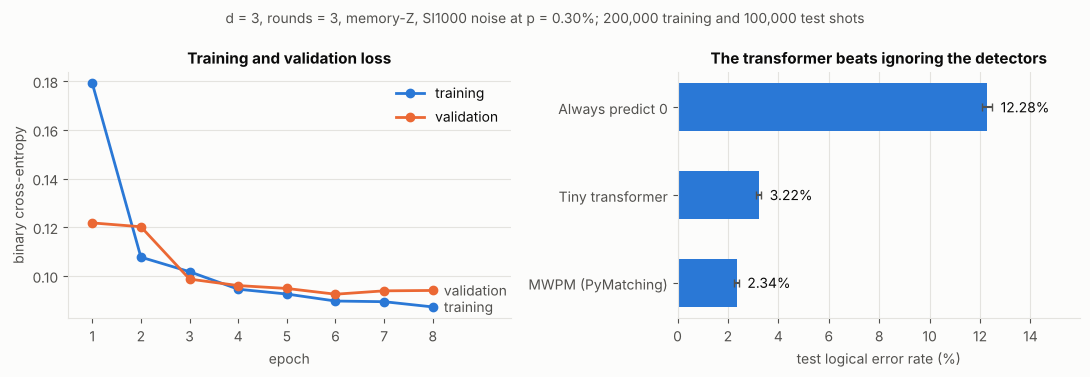

In [17]:
fig, (ax_loss, ax_bar) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})

# Left: loss per epoch. Training loss is the average over the epoch while the weights were still changing, so it
# sits slightly above the validation loss measured at the end of the same epoch.
epochs = np.arange(1, EPOCHS + 1)
for key, colour, name in [("train_loss", BLUE, "training"), ("val_loss", ORANGE, "validation")]:
    ax_loss.plot(epochs, history[key], color=colour, linewidth=2, marker="o", markersize=6, label=name)
    ax_loss.annotate(name, (epochs[-1], history[key][-1]), xytext=(8, 0), textcoords="offset points",
                     va="center", color=INK_2)
ax_loss.set_title("Training and validation loss")
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel("binary cross-entropy")
ax_loss.set_xticks(epochs)
ax_loss.set_xlim(0.5, EPOCHS + 1.6)
ax_loss.grid(axis="y", color=GRID, linewidth=0.8)
ax_loss.set_axisbelow(True)
ax_loss.legend(frameon=False)
for side in ("top", "right"):
    ax_loss.spines[side].set_visible(False)

# Right: test error rate of each decoder, one colour (one measure), labelled with its value.
names = list(results)
rates = [100 * results[n][0] for n in names]
cis = [100 * results[n][1] for n in names]
ypos = np.arange(len(names))[::-1]
ax_bar.barh(ypos, rates, xerr=cis, height=0.55, color=BLUE, error_kw={"ecolor": INK_2, "capsize": 3})
for yp, r, ci in zip(ypos, rates, cis):     # value label just past the end of the error bar
    ax_bar.annotate(f"{r:.2f}%", (r + ci, yp), xytext=(6, 0), textcoords="offset points", va="center", color=INK)
ax_bar.set_yticks(ypos, names)
ax_bar.set_xlabel("test logical error rate (%)")
ax_bar.set_xlim(0, max(rates) * 1.3)
ax_bar.set_axisbelow(True)                  # grid lines behind the bars
# The title states the outcome only if the intervals don't overlap, so it stays true for any config.
(r_zero, ci_zero), (r_tf, ci_tf) = results["Always predict 0"], results["Tiny transformer"]
beats = r_tf + ci_tf < r_zero - ci_zero
ax_bar.set_title("The transformer beats ignoring the detectors" if beats
                 else "The transformer does not beat ignoring the detectors")
ax_bar.grid(axis="x", color=GRID, linewidth=0.8)
for side in ("top", "right"):
    ax_bar.spines[side].set_visible(False)

noise_name = {"si1000": "SI1000", "uniform": "uniform"}[NOISE_MODEL]
fig.suptitle(f"d = {DISTANCE}, rounds = {ROUNDS}, memory-{BASIS.upper()}, {noise_name} noise at p = {P:.2%}; "
             f"{TRAIN_SHOTS:,} training and {TEST_SHOTS:,} test shots", fontsize=10, color=INK_2)
fig.tight_layout()
plt.show()

### What this shows

In the saved run (the shipped config: d = 3, 3 rounds, SI1000 noise at p = 0.3%, 200,000 training shots, 8 epochs, about 90 s of training on 4 CPU cores):

- **The preprocessing works with the transformer.** The tokens map back exactly to Stim's detection events (4.6), the model ignores padded tokens and token order as it should (5.2), and the loss falls steadily with validation tracking training.
- **The model learned from the tokens.** It gets 3.22% of the test shots wrong, against 12.28% for a decoder that ignores the detectors: 74% fewer errors. The tokens carry only detection events and fixed facts about each detector's place, so everything it learned came from the syndrome.
- **It is not a good decoder yet, as intended.** MWPM gets 2.34% wrong, so the tiny transformer makes 1.37 times as many errors. Closing that gap takes a bigger model, more data and longer training, which this notebook deliberately keeps small.

A rerun gives slightly different numbers on another machine or Stim version, and different ones for another config; the printed results above are always those of the current run.

### Where to go from here

The preprocessing and the model already handle everything below; each is a small change.

- **Turn on `"readings"`** in `extra_token_features` and compare the error rate.
- **Mix sizes**: sample shots for several d or round counts, pad every shot's tokens to the longest with `pad_mask = True` on the padding, and train one model on all of them. Section 5.2 shows the model already ignores padding.
- **Real-time decoding**: give the encoder an attention mask that blocks later rounds (`blocked = tok_round[None, :] > tok_round[:, None]` as a tensor, passed as `mask=`), so each token only reads its own and earlier rounds.
- **Accuracy** (not the goal here): more shots, more epochs, a wider model, training at a mix of noise levels with the noise prior as a feature, and stabilizer dropout.